In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import matplotlib.pyplot as plt
import numpy as np

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, ConcatDataset, random_split

import os

torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

BATCH_SIZE = 128
LEARNING_RATE = 0.001
EPOCHS = 30

print("Device:", device)
print("Batch Size:", BATCH_SIZE)
print("Learning Rate:", LEARNING_RATE)
print("Epochs:", EPOCHS)

Device: cuda
Batch Size: 128
Learning Rate: 0.001
Epochs: 30


In [2]:
transform = transforms.ToTensor()

original_train = datasets.FashionMNIST(
    root="../data",
    train=True,
    download=True,
    transform=transform
)

original_test = datasets.FashionMNIST(
    root="../data",
    train=False,
    download=True,
    transform=transform
)

full_dataset = ConcatDataset([
    original_train,
    original_test
])

total_size = len(full_dataset)

train_size = int(0.8 * total_size)
val_size = int(0.1 * total_size)
test_size = total_size - train_size - val_size

generator_seed = torch.Generator().manual_seed(42)

train_dataset, val_dataset, test_dataset = random_split(
    full_dataset,
    [train_size, val_size, test_size],
    generator=generator_seed
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 56000
Validation: 7000
Testing: 7000


In [3]:
class MLPClassifier(nn.Module):

    def __init__(self):
        super(MLPClassifier, self).__init__()

        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):

        x = x.view(x.size(0), 784)

        h1 = F.relu(self.fc1(x))

        z = F.relu(self.fc2(h1))

        output = self.fc3(z)

        return output

    def encode(self, x):

        x = x.view(x.size(0), 784)

        h1 = F.relu(self.fc1(x))

        z = F.relu(self.fc2(h1))

        return z

In [4]:
model = MLPClassifier().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print(model)

MLPClassifier(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)


In [5]:
def train_mlp(model, train_loader, val_loader, epochs):

    train_losses = []
    val_losses = []

    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):

        # Training
        model.train()

        total_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        avg_train_loss = total_loss / len(train_loader)
        train_accuracy = 100 * correct / total

        # Validation
        model.eval()

        val_loss = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                val_loss += loss.item()

                predictions = outputs.argmax(dim=1)

                val_correct += (
                    predictions == labels
                ).sum().item()

                val_total += labels.size(0)

        avg_val_loss = val_loss / len(val_loader)
        val_accuracy = 100 * val_correct / val_total

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)

        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {avg_train_loss:.4f} "
            f"Train Acc: {train_accuracy:.2f}% "
            f"Val Loss: {avg_val_loss:.4f} "
            f"Val Acc: {val_accuracy:.2f}%"
        )

    return (
        train_losses,
        val_losses,
        train_accuracies,
        val_accuracies
    )

In [6]:
(
    train_losses,
    val_losses,
    train_accuracies,
    val_accuracies
) = train_mlp(
    model,
    train_loader,
    val_loader,
    EPOCHS
)

Epoch [1/30] Train Loss: 0.6082 Train Acc: 78.90% Val Loss: 0.4701 Val Acc: 83.39%
Epoch [2/30] Train Loss: 0.4095 Train Acc: 85.52% Val Loss: 0.4032 Val Acc: 85.09%
Epoch [3/30] Train Loss: 0.3630 Train Acc: 86.97% Val Loss: 0.3730 Val Acc: 86.51%
Epoch [4/30] Train Loss: 0.3353 Train Acc: 87.86% Val Loss: 0.3622 Val Acc: 86.80%
Epoch [5/30] Train Loss: 0.3132 Train Acc: 88.65% Val Loss: 0.3393 Val Acc: 87.41%
Epoch [6/30] Train Loss: 0.2987 Train Acc: 89.03% Val Loss: 0.3451 Val Acc: 87.49%
Epoch [7/30] Train Loss: 0.2861 Train Acc: 89.46% Val Loss: 0.3221 Val Acc: 88.27%
Epoch [8/30] Train Loss: 0.2736 Train Acc: 89.93% Val Loss: 0.3346 Val Acc: 87.94%
Epoch [9/30] Train Loss: 0.2635 Train Acc: 90.23% Val Loss: 0.3317 Val Acc: 88.13%
Epoch [10/30] Train Loss: 0.2545 Train Acc: 90.56% Val Loss: 0.3193 Val Acc: 88.57%
Epoch [11/30] Train Loss: 0.2458 Train Acc: 90.91% Val Loss: 0.3238 Val Acc: 88.36%
Epoch [12/30] Train Loss: 0.2352 Train Acc: 91.26% Val Loss: 0.3087 Val Acc: 89.30%
E

In [7]:
model.eval()

test_correct = 0
test_total = 0
test_loss = 0.0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        test_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_accuracy = 100 * test_correct / test_total
avg_test_loss = test_loss / len(test_loader)

print("Test Loss:", avg_test_loss)
print(f"Test Accuracy: {test_accuracy:.2f}%")
print("Correct Predictions:", test_correct)
print("Total Test Samples:", test_total)

Test Loss: 0.3854621228846637
Test Accuracy: 89.14%
Correct Predictions: 6240
Total Test Samples: 7000


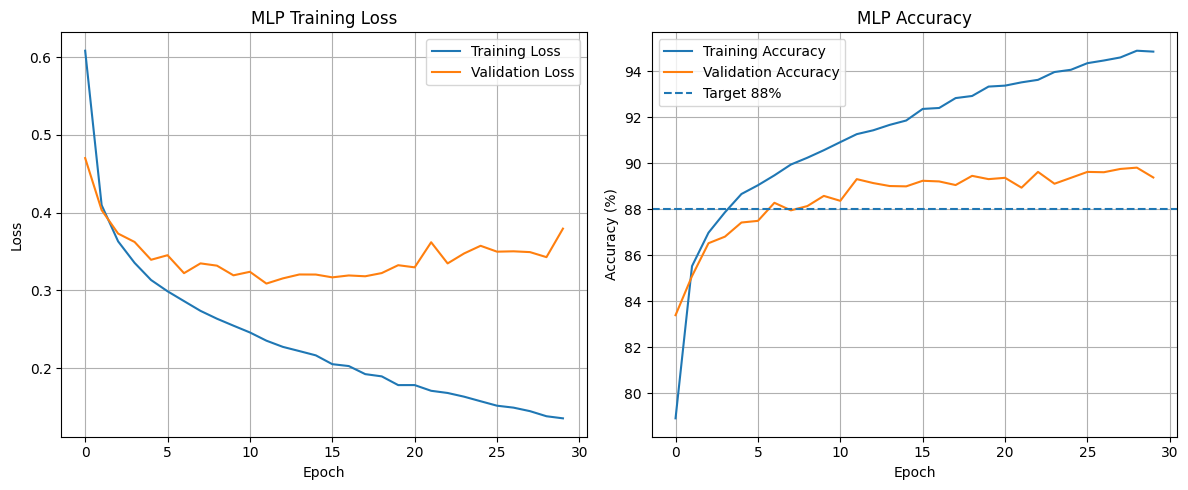

In [9]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.title("MLP Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")
plt.axhline(y=88, linestyle="--", label="Target 88%")
plt.title("MLP Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [10]:
os.makedirs("../results/checkpoints", exist_ok=True)

torch.save(
    model.state_dict(),
    "../results/checkpoints/mlp_classifier.pth"
)

print("MLP Classifier saved successfully!")

MLP Classifier saved successfully!


In [11]:
W1 = model.fc1.weight.detach().clone()
W2 = model.fc2.weight.detach().clone()
W3 = model.fc3.weight.detach().clone()

b1 = model.fc1.bias.detach().clone()
b2 = model.fc2.bias.detach().clone()
b3 = model.fc3.bias.detach().clone()

print("W1:", W1.shape)
print("W2:", W2.shape)
print("W3:", W3.shape)

W1: torch.Size([256, 784])
W2: torch.Size([64, 256])
W3: torch.Size([10, 64])


In [12]:
model.eval()

latent_features = []
test_images_list = []
test_labels_list = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        z = model.encode(images)

        latent_features.append(z.cpu())
        test_images_list.append(images.cpu())
        test_labels_list.append(labels)

z_mlp = torch.cat(latent_features, dim=0)
test_images_all = torch.cat(test_images_list, dim=0)
test_labels_all = torch.cat(test_labels_list, dim=0)

print("Latent Features:", z_mlp.shape)
print("Test Images:", test_images_all.shape)
print("Test Labels:", test_labels_all.shape)

Latent Features: torch.Size([7000, 64])
Test Images: torch.Size([7000, 1, 28, 28])
Test Labels: torch.Size([7000])


In [13]:
torch.save({
    "W1": W1.cpu(),
    "W2": W2.cpu(),
    "W3": W3.cpu(),
    "b1": b1.cpu(),
    "b2": b2.cpu(),
    "b3": b3.cpu(),
    "z_mlp": z_mlp,
    "test_images": test_images_all,
    "test_labels": test_labels_all,
    "test_accuracy": test_accuracy
}, "../results/checkpoints/mlp_experiment_data.pth")

print("MLP experiment data saved!")

MLP experiment data saved!


In [14]:
# Create 10 one-hot class vectors
num_classes = 10

one_hot = torch.eye(num_classes).to(device)

# Move weights to GPU
W1_gpu = W1.to(device)
W2_gpu = W2.to(device)
W3_gpu = W3.to(device)

# Reverse projection
with torch.no_grad():

    # 10 -> 64
    z_hat = F.relu(one_hot @ W3_gpu)

    # 64 -> 256
    h_hat = F.relu(z_hat @ W2_gpu)

    # 256 -> 784
    x_hat = torch.sigmoid(h_hat @ W1_gpu)

print("One-hot Shape:", one_hot.shape)
print("Projected Latent Shape:", z_hat.shape)
print("Hidden Shape:", h_hat.shape)
print("Generated Images Shape:", x_hat.shape)

One-hot Shape: torch.Size([10, 10])
Projected Latent Shape: torch.Size([10, 64])
Hidden Shape: torch.Size([10, 256])
Generated Images Shape: torch.Size([10, 784])


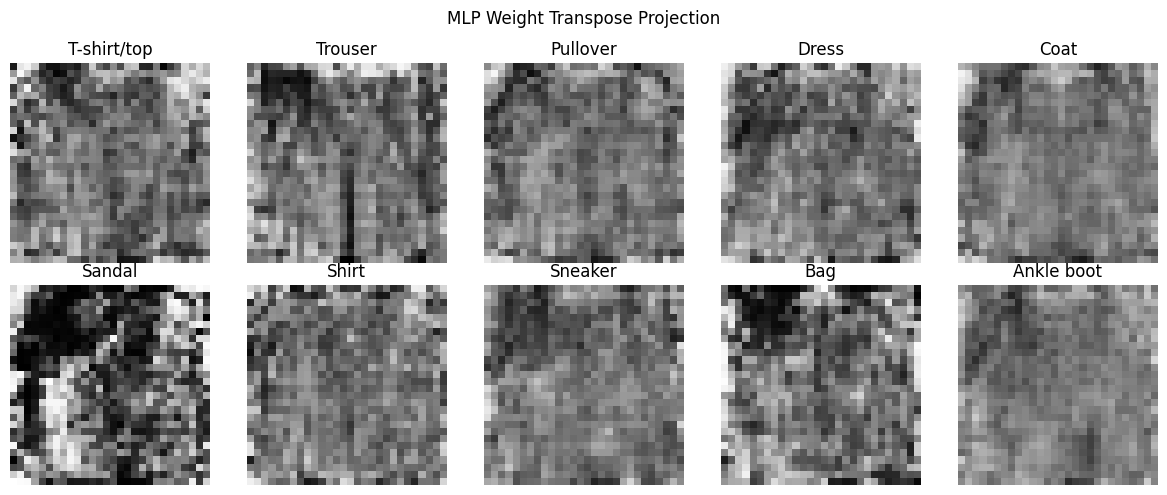

In [15]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

plt.figure(figsize=(12, 5))

for i in range(10):

    image = x_hat[i].cpu().reshape(28, 28)

    plt.subplot(2, 5, i + 1)
    plt.imshow(image, cmap="gray", vmin=0, vmax=1)
    plt.title(class_names[i])
    plt.axis("off")

plt.suptitle("MLP Weight Transpose Projection")
plt.tight_layout()
plt.show()

In [16]:
model.eval()

# Ambil 8 latent features dari test set
z_sample = z_mlp[:8].to(device)

with torch.no_grad():

    # 64 -> 256
    h_hat = F.relu(z_sample @ W2_gpu)

    # 256 -> 784
    reconstructed = torch.sigmoid(
        h_hat @ W1_gpu
    )

print("Latent Input Shape:", z_sample.shape)
print("Hidden Shape:", h_hat.shape)
print("Reconstructed Shape:", reconstructed.shape)

Latent Input Shape: torch.Size([8, 64])
Hidden Shape: torch.Size([8, 256])
Reconstructed Shape: torch.Size([8, 784])


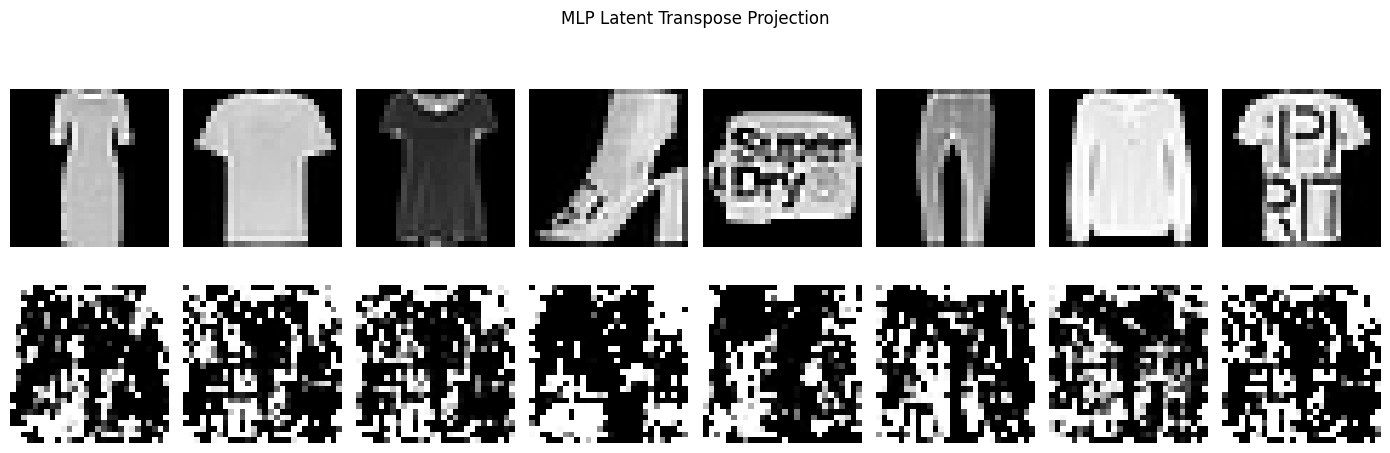

In [17]:
plt.figure(figsize=(14, 5))

for i in range(8):

    # Original image
    original = test_images_all[i].squeeze()

    # Reconstructed image
    reconstruction = reconstructed[i].cpu().reshape(28, 28)

    # Original row
    plt.subplot(2, 8, i + 1)
    plt.imshow(original, cmap="gray")
    plt.axis("off")

    if i == 0:
        plt.ylabel("Original")

    # Reconstructed row
    plt.subplot(2, 8, i + 9)
    plt.imshow(reconstruction, cmap="gray")
    plt.axis("off")

    if i == 0:
        plt.ylabel("Transpose")

plt.suptitle("MLP Latent Transpose Projection")
plt.tight_layout()
plt.show()

In [18]:
# Freeze all MLP parameters
for param in model.parameters():
    param.requires_grad = False

model.eval()

print("MLP parameters frozen!")

for name, param in model.named_parameters():
    print(name, param.requires_grad)

MLP parameters frozen!
fc1.weight False
fc1.bias False
fc2.weight False
fc2.bias False
fc3.weight False
fc3.bias False


In [19]:
def extract_latent_data(model, loader):

    latent_list = []
    image_list = []

    model.eval()

    with torch.no_grad():

        for images, _ in loader:

            images = images.to(device)

            latent = model.encode(images)

            latent_list.append(latent.cpu())
            image_list.append(images.cpu())

    return (
        torch.cat(latent_list, dim=0),
        torch.cat(image_list, dim=0)
    )


z_train, x_train = extract_latent_data(
    model, train_loader
)

z_val, x_val = extract_latent_data(
    model, val_loader
)

print("Training Latent:", z_train.shape)
print("Training Images:", x_train.shape)

print("Validation Latent:", z_val.shape)
print("Validation Images:", x_val.shape)

Training Latent: torch.Size([56000, 64])
Training Images: torch.Size([56000, 1, 28, 28])
Validation Latent: torch.Size([7000, 64])
Validation Images: torch.Size([7000, 1, 28, 28])


In [20]:
class MLPDecoder(nn.Module):

    def __init__(self):
        super(MLPDecoder, self).__init__()

        self.decoder = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),

            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, z):

        x = self.decoder(z)

        return x.view(-1, 1, 28, 28)


decoder = MLPDecoder().to(device)

print(decoder)

MLPDecoder(
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [21]:
from torch.utils.data import TensorDataset

train_decoder_dataset = TensorDataset(
    z_train,
    x_train
)

val_decoder_dataset = TensorDataset(
    z_val,
    x_val
)

train_decoder_loader = DataLoader(
    train_decoder_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_decoder_loader = DataLoader(
    val_decoder_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Decoder Training Batches:", len(train_decoder_loader))
print("Decoder Validation Batches:", len(val_decoder_loader))

Decoder Training Batches: 438
Decoder Validation Batches: 55


In [22]:
DECODER_EPOCHS = 30
DECODER_LR = 0.001

decoder_criterion = nn.MSELoss()

decoder_optimizer = optim.Adam(
    decoder.parameters(),
    lr=DECODER_LR
)

print("Decoder optimizer initialized!")
print("Learning Rate:", DECODER_LR)
print("Epochs:", DECODER_EPOCHS)

Decoder optimizer initialized!
Learning Rate: 0.001
Epochs: 30


In [23]:
def train_mlp_decoder(
    decoder,
    train_loader,
    val_loader,
    epochs
):
    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        # Training
        decoder.train()
        train_loss = 0.0

        for latent, images in train_loader:

            latent = latent.to(device)
            images = images.to(device)

            decoder_optimizer.zero_grad()

            reconstructed = decoder(latent)

            loss = decoder_criterion(
                reconstructed,
                images
            )

            loss.backward()
            decoder_optimizer.step()

            train_loss += loss.item()

        avg_train_loss = train_loss / len(train_loader)

        # Validation
        decoder.eval()
        val_loss = 0.0

        with torch.no_grad():

            for latent, images in val_loader:

                latent = latent.to(device)
                images = images.to(device)

                reconstructed = decoder(latent)

                loss = decoder_criterion(
                    reconstructed,
                    images
                )

                val_loss += loss.item()

        avg_val_loss = val_loss / len(val_loader)

        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"Train Loss: {avg_train_loss:.6f} "
            f"Val Loss: {avg_val_loss:.6f}"
        )

    return train_losses, val_losses

In [24]:
decoder_train_losses, decoder_val_losses = train_mlp_decoder(
    decoder,
    train_decoder_loader,
    val_decoder_loader,
    DECODER_EPOCHS
)

Epoch [1/30] Train Loss: 0.036178 Val Loss: 0.027323
Epoch [2/30] Train Loss: 0.025262 Val Loss: 0.024240
Epoch [3/30] Train Loss: 0.023102 Val Loss: 0.022802
Epoch [4/30] Train Loss: 0.021962 Val Loss: 0.022362
Epoch [5/30] Train Loss: 0.021190 Val Loss: 0.021272
Epoch [6/30] Train Loss: 0.020634 Val Loss: 0.020718
Epoch [7/30] Train Loss: 0.020174 Val Loss: 0.020338
Epoch [8/30] Train Loss: 0.019811 Val Loss: 0.020143
Epoch [9/30] Train Loss: 0.019519 Val Loss: 0.019896
Epoch [10/30] Train Loss: 0.019284 Val Loss: 0.019852
Epoch [11/30] Train Loss: 0.019079 Val Loss: 0.019504
Epoch [12/30] Train Loss: 0.018909 Val Loss: 0.019650
Epoch [13/30] Train Loss: 0.018740 Val Loss: 0.019310
Epoch [14/30] Train Loss: 0.018644 Val Loss: 0.019182
Epoch [15/30] Train Loss: 0.018511 Val Loss: 0.019231
Epoch [16/30] Train Loss: 0.018377 Val Loss: 0.018941
Epoch [17/30] Train Loss: 0.018293 Val Loss: 0.018882
Epoch [18/30] Train Loss: 0.018193 Val Loss: 0.018989
Epoch [19/30] Train Loss: 0.018144 Va

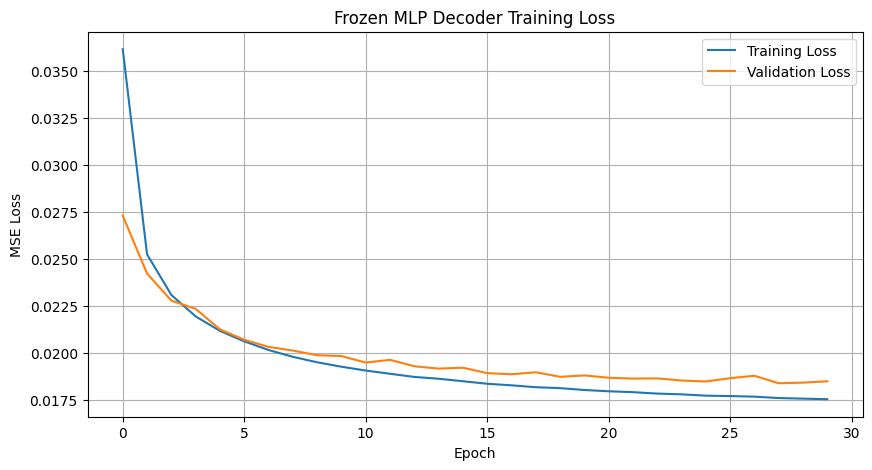

In [25]:
plt.figure(figsize=(10, 5))

plt.plot(
    decoder_train_losses,
    label="Training Loss"
)

plt.plot(
    decoder_val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Frozen MLP Decoder Training Loss")

plt.legend()
plt.grid(True)
plt.show()

In [26]:
torch.save(
    decoder.state_dict(),
    "../results/checkpoints/mlp_frozen_decoder.pth"
)

print("Frozen MLP Decoder saved successfully!")

Frozen MLP Decoder saved successfully!


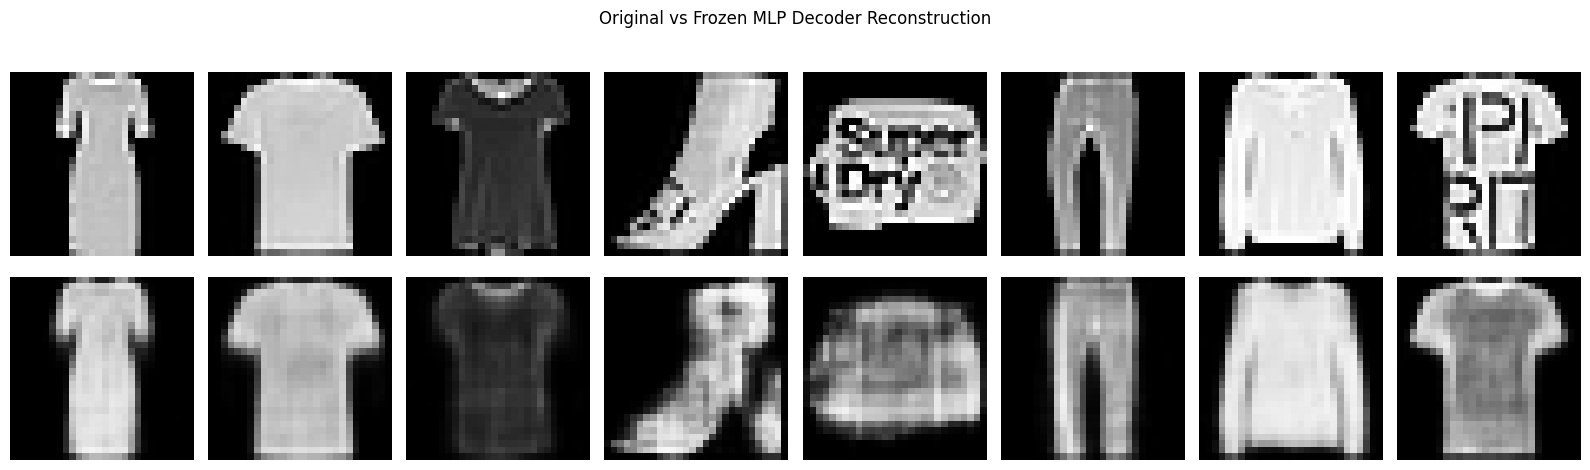

In [27]:
decoder.eval()
model.eval()

# Ambil 8 gambar test
original_images = test_images_all[:8].to(device)
latent_test = z_mlp[:8].to(device)

with torch.no_grad():
    reconstructed_images = decoder(latent_test)

plt.figure(figsize=(16, 5))

for i in range(8):
    # Original
    plt.subplot(2, 8, i + 1)
    plt.imshow(
        original_images[i].cpu().squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    plt.axis("off")

    # Reconstruction
    plt.subplot(2, 8, i + 9)
    plt.imshow(
        reconstructed_images[i].cpu().squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    plt.axis("off")

plt.suptitle("Original vs Frozen MLP Decoder Reconstruction")
plt.tight_layout()
plt.show()

In [28]:
from skimage.metrics import (
    structural_similarity as ssim,
    peak_signal_noise_ratio as psnr
)

decoder.eval()

mse_scores = []
psnr_scores = []
ssim_scores = []

with torch.no_grad():
    for start in range(0, len(z_mlp), BATCH_SIZE):

        z_batch = z_mlp[start:start+BATCH_SIZE].to(device)
        x_batch = test_images_all[start:start+BATCH_SIZE]

        recon_batch = decoder(z_batch).cpu()

        for original, recon in zip(x_batch, recon_batch):

            original = original.squeeze().numpy()
            recon = recon.squeeze().numpy()

            mse_scores.append(
                np.mean((original - recon) ** 2)
            )

            psnr_scores.append(
                psnr(original, recon, data_range=1.0)
            )

            ssim_scores.append(
                ssim(original, recon, data_range=1.0)
            )

print("Frozen MLP Decoder Evaluation")
print("MSE:", np.mean(mse_scores))
print("PSNR:", np.mean(psnr_scores))
print("SSIM:", np.mean(ssim_scores))

Frozen MLP Decoder Evaluation
MSE: 0.018368214
PSNR: 18.163758184117576
SSIM: 0.6547778403540028


In [29]:
# Calculate latent distribution
z_mean = z_train.mean(dim=0)
z_std = z_train.std(dim=0)

print("Latent Mean Shape:", z_mean.shape)
print("Latent Std Shape:", z_std.shape)

print("Mean of Latent Distribution:", z_mean.mean().item())
print("Std of Latent Distribution:", z_std.mean().item())

Latent Mean Shape: torch.Size([64])
Latent Std Shape: torch.Size([64])
Mean of Latent Distribution: 1.5962989330291748
Std of Latent Distribution: 2.072003126144409


In [30]:
NUM_GENERATED = 16

z_random = (
    z_mean.unsqueeze(0)
    + z_std.unsqueeze(0) * torch.randn(
        NUM_GENERATED,
        64
    )
)

z_random = z_random.to(device)

print("Random Latent Shape:", z_random.shape)
print("Device:", z_random.device)

Random Latent Shape: torch.Size([16, 64])
Device: cuda:0


In [31]:
decoder.eval()

with torch.no_grad():

    generated_mlp = decoder(z_random)

print("Generated Images Shape:", generated_mlp.shape)

Generated Images Shape: torch.Size([16, 1, 28, 28])


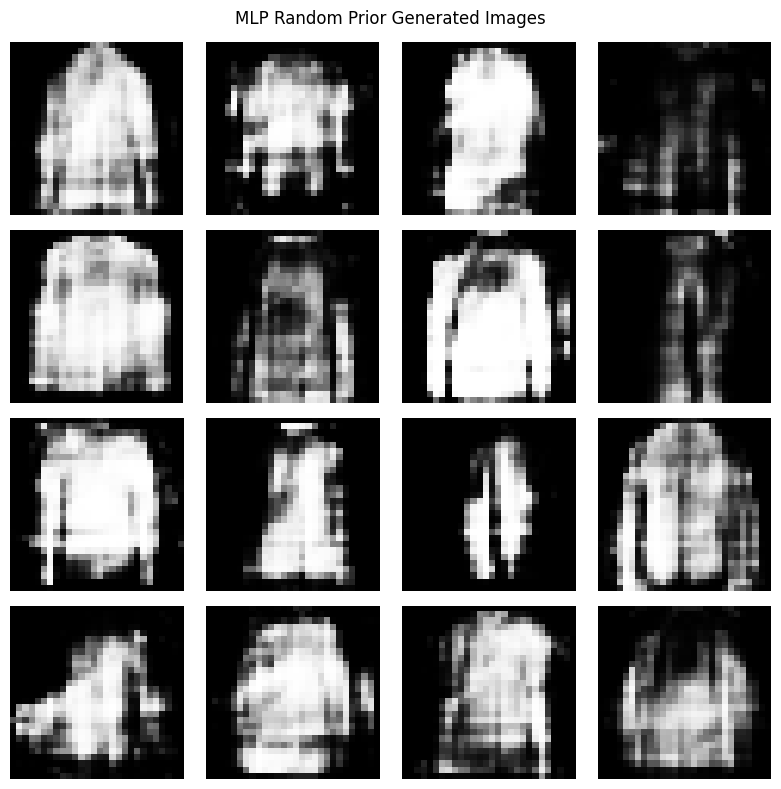

In [32]:
plt.figure(figsize=(8, 8))

for i in range(NUM_GENERATED):

    plt.subplot(4, 4, i + 1)

    plt.imshow(
        generated_mlp[i].cpu().squeeze(),
        cmap="gray",
        vmin=0,
        vmax=1
    )

    plt.axis("off")

plt.suptitle("MLP Random Prior Generated Images")
plt.tight_layout()
plt.show()

In [33]:
import os
from torchvision.utils import save_image

os.makedirs("../results/generated_images", exist_ok=True)
os.makedirs("../results/checkpoints", exist_ok=True)
os.makedirs("../results/metrics", exist_ok=True)

# Save random generated images
save_image(
    generated_mlp.cpu(),
    "../results/generated_images/mlp_random_prior.png",
    nrow=4
)

# Save transpose projection
save_image(
    x_hat.cpu().view(-1, 1, 28, 28),
    "../results/generated_images/mlp_weight_transpose.png",
    nrow=5
)

# Save latent transpose projection
save_image(
    reconstructed.cpu().view(-1, 1, 28, 28),
    "../results/generated_images/mlp_latent_transpose.png",
    nrow=4
)

# Save frozen decoder reconstruction
save_image(
    reconstructed_images.cpu(),
    "../results/generated_images/mlp_frozen_decoder.png",
    nrow=4
)

# Save frozen decoder
torch.save(
    decoder.state_dict(),
    "../results/checkpoints/mlp_frozen_decoder.pth"
)

print("All MLP experiment results saved!")

All MLP experiment results saved!
